# Compare traces from ai/ND pipelines to variant traces from Photon Mosaic
## Compare with CaImAn, Suite2p circular and Suite2p surround
Loads the registered (decrosstalked) movie from a single plane of one of our multi-plane imaging sessions. This compares
neuropil handling in photon-mosaic against three outputs from our pipeline: CaImAn, Suite2p with circular neuropil, and
Suite2p with surround neuropil. Every section below runs for all three sources.

The photon-mosaic variants only depend on the ROI masks, so they are computed once per unique ROI set: the two Suite2p
extractions share the same masks (only `iscell` differs) and reuse the same results.

In [23]:
from pathlib import Path

import spikeinterface.widgets as sw

import h5py
import matplotlib.pyplot as plt
import numpy as np
import sparse

import photon_mosaic as pm
from photon_mosaic.core.numpyimaging import NumpyRois

%matplotlib inline

## Paths and settings

The decrosstalk movie is ~19 GB (35711 x 512 x 512, int16), so only a frame window is loaded into memory
(~0.5 MB/frame). Paste the path to the decrosstalk movie to create the imaging object, and add one entry to `SOURCES`
per extraction file (whichever algorithm was used to extract fluorescence, neuropil and df/f).

Per source, `dff_variant` / `dff_roi` are the defaults used by `compare_dff` and the example-ROI plots below.

In [24]:
PLANE_DIR = Path("../data/multiplane-ophys_853372_2026-10-13_09-56-31_processed_2026-10-14_20-39-39/VISp_0")
MOVIE_H5 = PLANE_DIR / "decrosstalk" / "VISp_0_decrosstalk.h5"

SOURCES = {
    "caiman": dict(
        extraction_h5="/data/greedy_roi_cnmf0/VISp_0/extraction/VISp_0_extraction.h5",
        dff_variant="cnmf gnb=1",
        dff_roi=19,
    ),
    "cnmf (al_cnmf_ar0)": dict(
        extraction_h5="../data/al_cnmf_ar0/extraction/VISp_0_extraction.h5",
        dff_variant="cnmf gnb=1 nnls",
        dff_roi=19,
    ),
    "suite2p circular": dict(
        extraction_h5="/data/extraction_suite2p_neuropil0/extraction/VISp_0_extraction.h5",
        dff_variant="surround circular",
        dff_roi=11,
    ),
    "suite2p surround": dict(
        extraction_h5="/data/extraction_suite2p_surround/VISp_0/extraction/VISp_0_extraction.h5",
        dff_variant="surround w=0.7",
        dff_roi=11,
    ),
}

SAMPLING_FREQUENCY = 9.44
START_FRAME, N_FRAMES = 0, 5000
N_JOBS = 4
FIG_DIR = Path("../results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def slug(name):
    return name.replace(" ", "_")

## Load ROIs and reference traces

`rois/coords` is `(roi, y, x)` with per-pixel weights in `rois/data`. Each source gets its own entry in `data`.

In [25]:
data = {}
for name, cfg in SOURCES.items():
    with h5py.File(cfg["extraction_h5"]) as h:
        coords = h["rois/coords"][:].astype(int)
        weights = h["rois/data"][:]
        shape = tuple(int(s) for s in h["rois/shape"][:])  # (n_rois, Ly, Lx)
        d = dict(
            iscell=h["iscell"][:, 0].astype(bool),
            ref={k: h[f"traces/{k}"][:, START_FRAME : START_FRAME + N_FRAMES] for k in ("roi", "neuropil", "corrected")},
            mean_img=h["meanImg"][:],
            ref_dff=h["dFF/ls"][:, START_FRAME : START_FRAME + N_FRAMES],  # (roi, frame)
            coords=coords,
            weights=weights,
            shape=shape,
        )
    masks = sparse.COO(coords, weights, shape=shape).asformat("gcxs")
    d["rois"] = NumpyRois(masks, sampling_frequency=SAMPLING_FREQUENCY)
    data[name] = d
    print(f"{name}: {shape}, ROIs flagged as cells: {d['iscell'].sum()}")


def same_masks(a, b):
    return a["shape"] == b["shape"] and np.array_equal(a["coords"], b["coords"]) and np.array_equal(a["weights"], b["weights"])


# sources with identical masks share photon-mosaic results
for i, name in enumerate(data):
    data[name]["roi_set"] = next(other for other in list(data)[: i + 1] if same_masks(data[other], data[name]))
roi_sets = sorted(set(d["roi_set"] for d in data.values()), key=list(data).index)
print("unique ROI sets:", {s: [n for n in data if data[n]["roi_set"] == s] for s in roi_sets})

caiman: (253, 512, 512), ROIs flagged as cells: 120
cnmf (al_cnmf_ar0): (255, 512, 512), ROIs flagged as cells: 197
suite2p circular: (101, 512, 512), ROIs flagged as cells: 48
suite2p surround: (101, 512, 512), ROIs flagged as cells: 47
unique ROI sets: {'caiman': ['caiman'], 'cnmf (al_cnmf_ar0)': ['cnmf (al_cnmf_ar0)'], 'suite2p circular': ['suite2p circular', 'suite2p surround']}


## Load a window of the movie

In [26]:
with h5py.File(MOVIE_H5) as h:
    movie = h["data"][START_FRAME : START_FRAME + N_FRAMES]
imaging = pm.NumpyImaging(movie, sampling_frequency=SAMPLING_FREQUENCY)
imaging

NumpyImaging:
9.440000 Hz - 1 epochs - 512 rows x 512 columns  - 529.66s (8.83 minutes) - int16 dtype - 2.44 GiB

In [27]:
import photon_mosaic.widgets as pw
%matplotlib widget
w = pw.plot_imaging_series(imaging, backend="ipywidgets", vmax_percentile=99.75)
w.colorbars["imaging"].set_label("Photon counts")
w.figure.tight_layout()  # re-run: the label wasn't there for the widget's own tight_layout() call

In [28]:
for roi_set in roi_sets:
    print(f"ROIs: {roi_set}")
    analyzer = pm.create_roi_analyzer(data[roi_set]["rois"], imaging)
    pw.plot_rois(analyzer.rois, imaging=analyzer.imaging, backend="ipywidgets", width_cm=20)

ROIs: caiman


ROIs: cnmf (al_cnmf_ar0)


/root/capsule/src/photon_mosaic/widgets/rois.py:190: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  self.figure, (self.ax_full, self.ax_zoom) = plt.subplots(1, 2, figsize=(width_cm * 2 * cm, height_cm * cm))


ROIs: suite2p circular


## Variants

Each variant gets a fresh analyzer so extension dependencies never leak between runs.
`'regression'` (or `'nnls'`) is used for the joint CNMF solve; `neuropil_weight` is ignored there.
Variants run once per unique ROI set; `data[name]["results"]` points at the shared dict.

In [29]:
def run_variant(rois, neuropil=None, background=None, **fluorescence_params):
    analyzer = pm.create_roi_analyzer(rois, imaging)
    if neuropil is not None:
        analyzer.compute("neuropil", **neuropil)
    if background is not None:
        analyzer.compute("background", n_jobs=N_JOBS, **background)
        fluorescence_ext_cnmf = analyzer.compute(
            "fluorescence", method="nnls", n_jobs=4, use_neuropil=True, neuropil_source="background"
        )
    ext = analyzer.compute("fluorescence", n_jobs=N_JOBS, **fluorescence_params)
    return analyzer, ext


VARIANTS = {
    "none": dict(use_neuropil=False),
    "surround w=0.7": dict(neuropil=dict(), neuropil_weight=0.7),
    "surround w=1.0": dict(neuropil=dict(), neuropil_weight=1.0),
    "surround circular": dict(neuropil=dict(circular=True), neuropil_weight=0.7),
    "surround inner=4": dict(neuropil=dict(inner_neuropil_radius=4), neuropil_weight=0.7),
    "cnmf gnb=1": dict(background=dict(gnb=1), method="regression"),
    "cnmf gnb=1 nnls": dict(background=dict(gnb=1), method="nnls"),
}

for roi_set in roi_sets:
    results = {}
    for name, kwargs in VARIANTS.items():
        analyzer, ext = run_variant(data[roi_set]["rois"], **kwargs)
        has_neuropil = "neuropil" in kwargs or "background" in kwargs
        results[name] = dict(
            analyzer=analyzer,
            F=ext.get_data(),
            bg=ext.get_data(key="background") if has_neuropil else None,
        )
        print(f"[{roi_set}] {name}", results[name]["F"].shape)
    for d in data.values():
        if d["roi_set"] == roi_set:
            d["results"] = results

fluorescence (workers: 4 processes fork):   0%|          | 0/556 [00:00<?, ?it/s]

[caiman] none (5000, 253)


fluorescence (workers: 4 processes fork):   0%|          | 0/556 [00:00<?, ?it/s]

[caiman] surround w=0.7 (5000, 253)


fluorescence (workers: 4 processes fork):   0%|          | 0/556 [00:00<?, ?it/s]

...

fluorescence (workers: 4 processes fork):   0%|          | 0/556 [00:00<?, ?it/s]

[suite2p circular] cnmf gnb=1 (5000, 101)


fluorescence (workers: 4 processes fork):   0%|          | 0/556 [00:00<?, ?it/s]

fluorescence (workers: 4 processes fork):   0%|          | 0/556 [00:00<?, ?it/s]

[suite2p circular] cnmf gnb=1 nnls (5000, 101)


In [30]:
for roi_set in roi_sets:
    print(f"ROIs: {roi_set}")
    fluor_ext = data[roi_set]["results"]["none"]["analyzer"].get_extension("fluorescence")
    fluor_none_ext = fluor_ext.get_data(outputs="recording")
    sw.plot_traces(fluor_none_ext, backend="ipywidgets")

ROIs: caiman


AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

ROIs: cnmf (al_cnmf_ar0)


AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

ROIs: suite2p circular


AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

In [31]:
import ipywidgets as ipw

t = np.arange(N_FRAMES) / SAMPLING_FREQUENCY
variant_names = list(VARIANTS)


def cell_ids(src):
    return [int(i) for i in np.flatnonzero(data[src]["iscell"])]


src_dd = ipw.Dropdown(options=list(data), description="Source")
roi_dd = ipw.Dropdown(options=cell_ids(src_dd.value), description="ROI")
trace_dd = ipw.Dropdown(options=["fluorescence", "neuropil / background"], description="Trace")
variant_sel = ipw.SelectMultiple(options=variant_names, value=variant_names[:2], rows=len(variant_names), description="Variants")
ref_cb = ipw.Checkbox(value=True, description="Pipeline reference", indent=False)
time_sl = ipw.FloatRangeSlider(
    value=[0, 60], min=0, max=float(t[-1]), step=1, description="Time (s)", layout=ipw.Layout(width="600px")
)

with plt.ioff():  # keep the widget backend from also auto-displaying the figure
    fig, ax = plt.subplots(figsize=(12, 4))
fig.canvas.header_visible = False


def redraw(*_):
    src, roi, kind = src_dd.value, roi_dd.value, trace_dd.value
    if roi is None:
        return
    d = data[src]
    ax.clear()
    for name in variant_sel.value:
        r = d["results"][name]
        y = r["F"][:, roi] if kind == "fluorescence" else (r["bg"][:, roi] if r["bg"] is not None else None)
        if y is not None:
            ax.plot(t, y, lw=0.8, label=name)
    if ref_cb.value:
        key = "corrected" if kind == "fluorescence" else "neuropil"
        ax.plot(t, d["ref"][key][roi], c="k", lw=0.8, alpha=0.6, label=f"{src} {key}")
    ax.set_xlim(*time_sl.value)
    ax.set_xlabel("Time (s)")
    ax.set_title(f"{src}: ROI {roi} - {kind}")
    ax.legend(ncol=3, fontsize=7)
    fig.canvas.draw_idle()


def on_source(*_):
    roi = roi_dd.value
    ids = cell_ids(src_dd.value)
    with roi_dd.hold_trait_notifications():
        roi_dd.options = ids
        roi_dd.value = roi if roi in ids else ids[0]
    redraw()


src_dd.observe(on_source, names="value")
for w in (roi_dd, trace_dd, variant_sel, ref_cb, time_sl):
    w.observe(redraw, names="value")
redraw()
ipw.VBox([ipw.HBox([ipw.VBox([src_dd, roi_dd, trace_dd, ref_cb]), variant_sel]), time_sl, fig.canvas])

## Agreement with the pipeline traces across ROIs

Correlation of each variant's trace with each source's neuropil-corrected trace (`traces/corrected`), cells only.
Absolute scale can differ from the pipeline, so correlation is the scale-free check. Also plots Pearson r<sup>2</sup>
and R<sup>2</sup> against the identity line. One row per source.

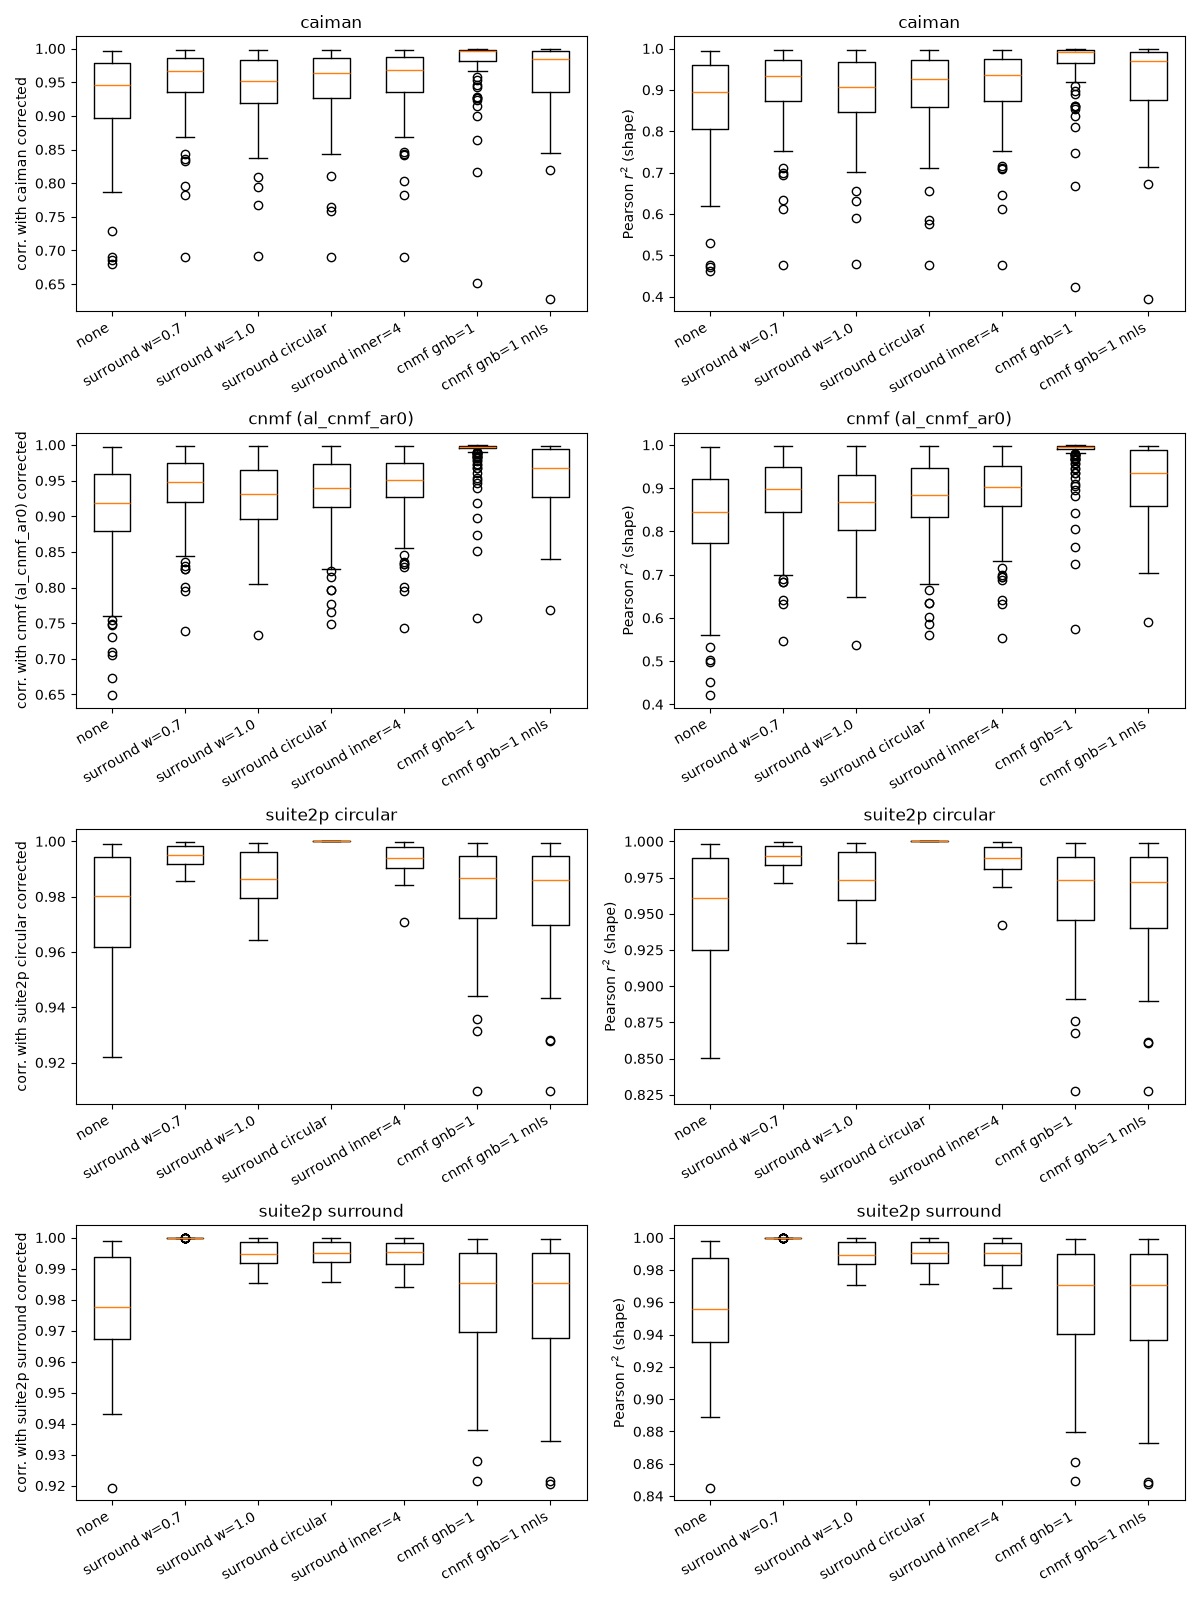

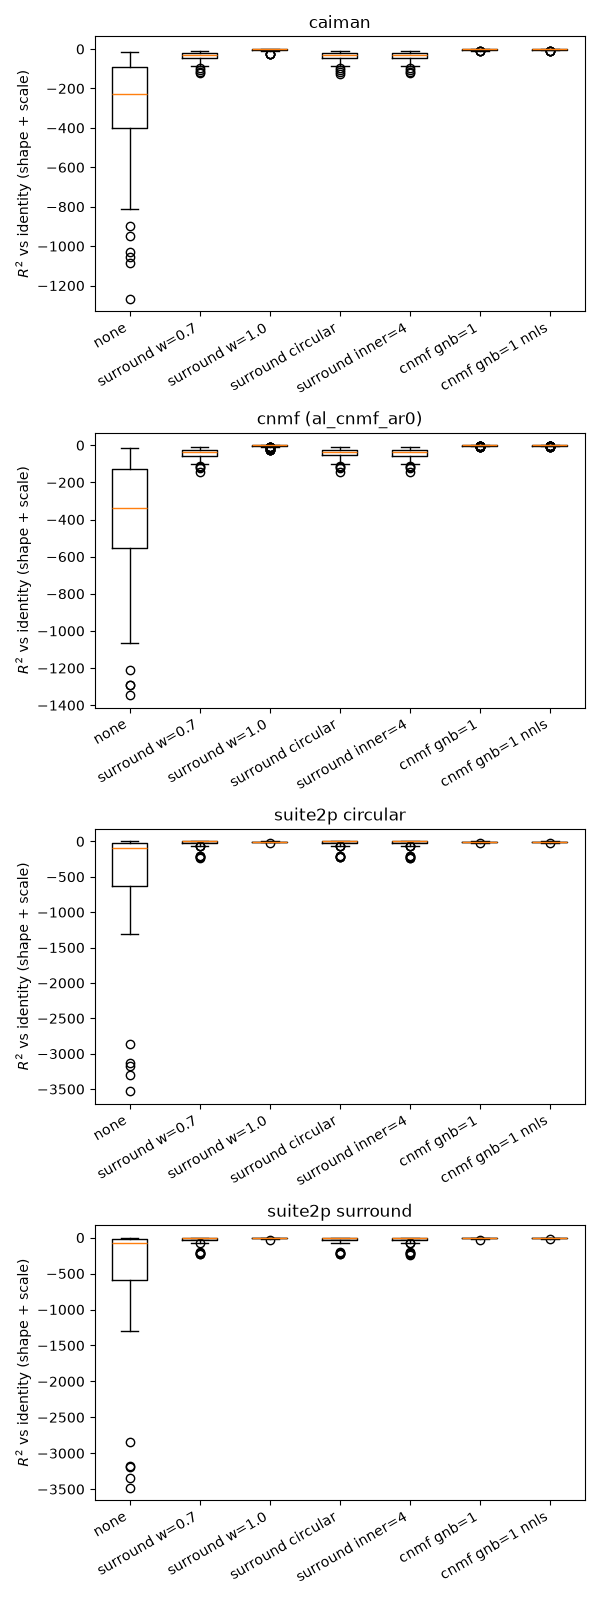

In [32]:
def corr_per_roi(a, b):
    a = a - a.mean(0)
    b = b - b.mean(0)
    return (a * b).sum(0) / np.sqrt((a**2).sum(0) * (b**2).sum(0))


def r2_identity_per_roi(y, y_ref):
    """R^2 of y against y_ref with no fitting (penalizes scale and offset differences; can be < 0)."""
    ss_res = ((y_ref - y) ** 2).sum(0)
    ss_tot = ((y_ref - y_ref.mean(0)) ** 2).sum(0)
    return 1 - ss_res / ss_tot


def boxplot_all_sources(metrics, filename):
    """One row per source; `metrics` maps a y-label to a function (src, d, name, r) -> per-cell values."""
    fig, axes = plt.subplots(len(data), len(metrics), figsize=(6 * len(metrics), 4 * len(data)), squeeze=False)
    for row, (src, d) in zip(axes, data.items()):
        corrected, iscell = d["ref"]["corrected"].T, d["iscell"]
        for ax, (label, fn) in zip(row, metrics.items()):
            vals = {name: fn(r["F"], corrected)[iscell] for name, r in d["results"].items()}
            ax.boxplot(list(vals.values()), tick_labels=list(vals))
            ax.set_ylabel(label.format(src=src))
            ax.set_title(src)
            plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, bbox_inches="tight")


boxplot_all_sources(
    {
        "corr. with {src} corrected": corr_per_roi,
        "Pearson $r^2$ (shape)": lambda a, b: corr_per_roi(a, b) ** 2,
    },
    "corr_with_pipeline_all_sources.pdf",
)
# separate figure: R^2 vs identity can be strongly negative and would squash the shape-only panels
boxplot_all_sources({"$R^2$ vs identity (shape + scale)": r2_identity_per_roi}, "r2_identity_with_pipeline_all_sources.pdf")


## Estimated neuropil / background traces

One panel per source, at that source's `dff_roi` (change `SOURCES[...]["dff_roi"]` or call `plot_background(src, roi)`).

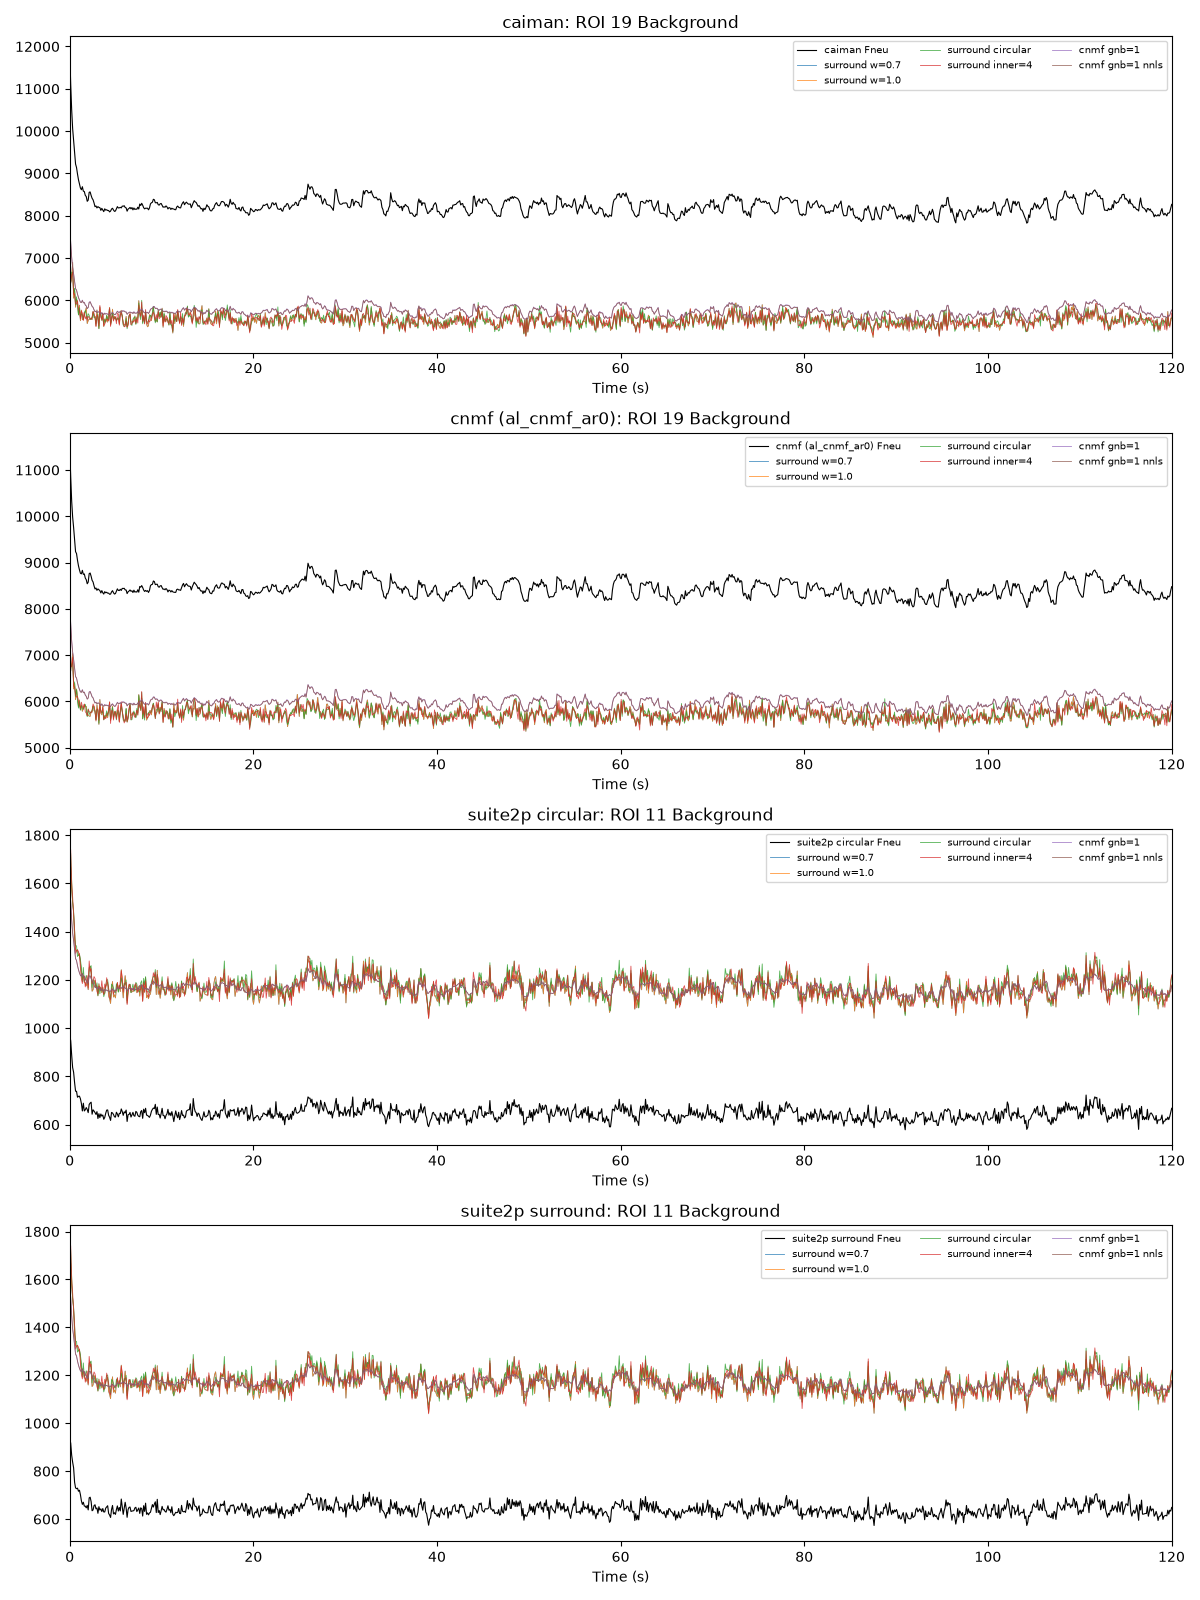

In [33]:
def plot_background(src, roi, ax=None):
    d = data[src]
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 4))
    ax.plot(t, d["ref"]["neuropil"][roi], c="k", lw=0.8, label=f"{src} Fneu")
    for name, r in d["results"].items():
        if r["bg"] is not None:
            ax.plot(t, r["bg"][:, roi], lw=0.6, alpha=0.8, label=name)
    ax.set_xlabel("Time (s)")
    ax.set_title(f"{src}: ROI {roi} Background")
    ax.legend(ncol=3, fontsize=7)
    ax.set_xlim(0, 120)
    return ax


fig, axes = plt.subplots(len(data), 1, figsize=(12, 4 * len(data)), squeeze=False)
for ax, (src, cfg) in zip(axes[:, 0], SOURCES.items()):
    plot_background(src, cfg["dff_roi"], ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "neuropil_background_traces_all_sources.pdf", bbox_inches="tight")

## dF/F: pipeline vs photon-mosaic

Neuropil subtraction lowers the baseline `F0`, so the same events usually give a *larger* dF/F. `compare_dff` shows
whether that holds per cell, and whether the correction improves event SNR (99th-percentile dF/F over robust
frame-to-frame noise) rather than only rescaling. Try any source and any variant name, e.g.
`compare_dff("caiman", "cnmf gnb=1 nnls")`.

dict_keys(['none', 'surround w=0.7', 'surround w=1.0', 'surround circular', 'surround inner=4', 'cnmf gnb=1', 'cnmf gnb=1 nnls'])
[caiman] cnmf gnb=1 vs caiman dF/F (n=120 cells): median peak dF/F 0.299 vs 0.296, median SNR 4.8 vs 4.8
dict_keys(['none', 'surround w=0.7', 'surround w=1.0', 'surround circular', 'surround inner=4', 'cnmf gnb=1', 'cnmf gnb=1 nnls'])
[cnmf (al_cnmf_ar0)] cnmf gnb=1 nnls vs cnmf (al_cnmf_ar0) dF/F (n=197 cells): median peak dF/F 0.211 vs 0.233, median SNR 5.4 vs 4.6
dict_keys(['none', 'surround w=0.7', 'surround w=1.0', 'surround circular', 'surround inner=4', 'cnmf gnb=1', 'cnmf gnb=1 nnls'])


/tmp/ipykernel_1076/3875828956.py:41: RuntimeWarning: divide by zero encountered in divide
  out["snr_var"] = out["peak_var"] / out["noise_var"]


[suite2p circular] surround circular vs suite2p circular dF/F (n=48 cells): median peak dF/F 0.907 vs 0.669, median SNR 5.2 vs 4.2
dict_keys(['none', 'surround w=0.7', 'surround w=1.0', 'surround circular', 'surround inner=4', 'cnmf gnb=1', 'cnmf gnb=1 nnls'])
[suite2p surround] surround w=0.7 vs suite2p surround dF/F (n=47 cells): median peak dF/F 0.911 vs 0.672, median SNR 5.2 vs 4.2


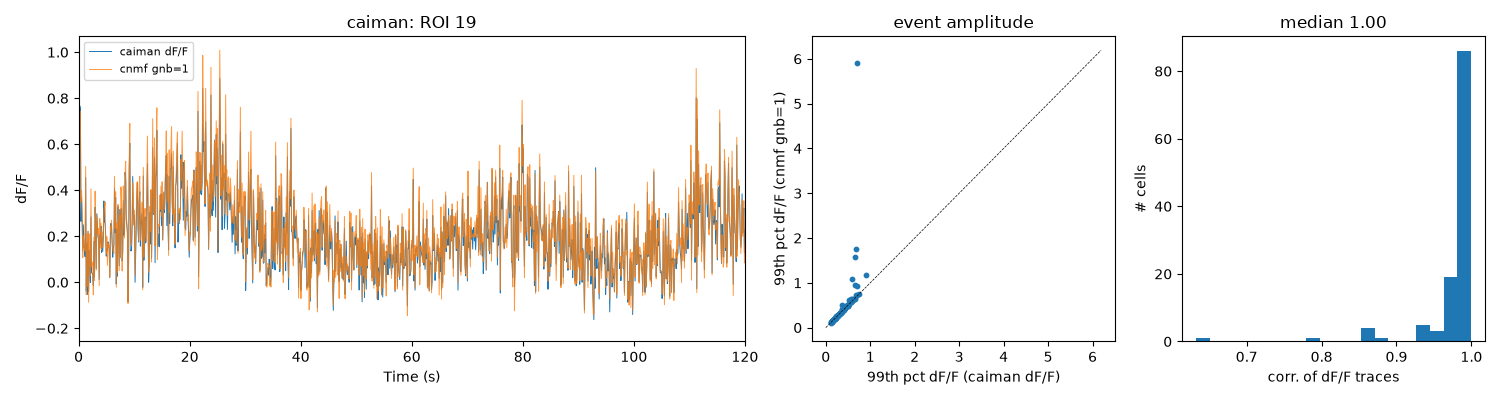

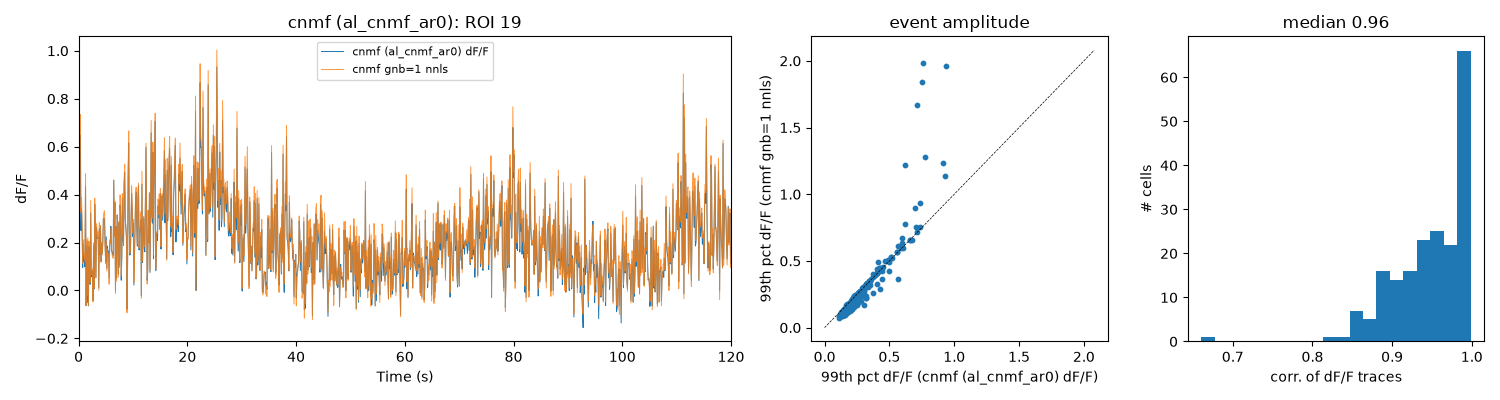

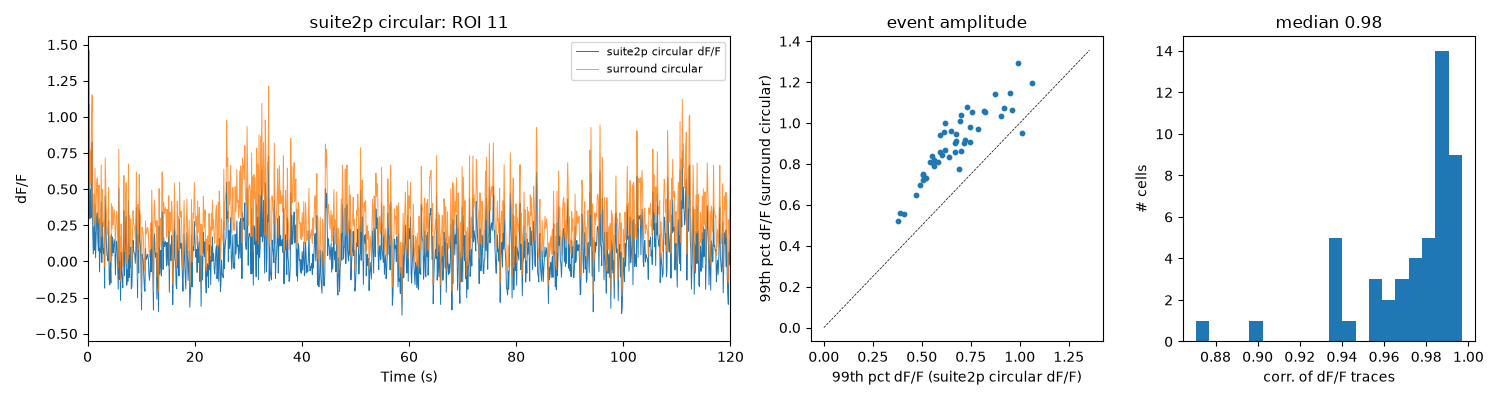

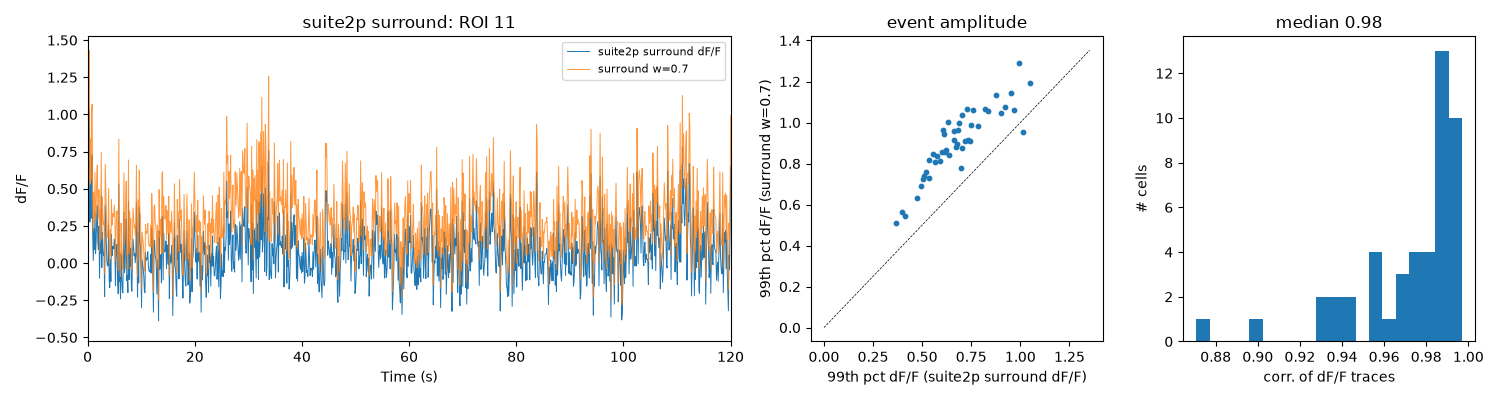

In [34]:
def compute_dff(src, name, **dff_params):
    """dF/F of one variant's fluorescence (recomputed, so `dff_params` always apply)."""
    print(data[src]['results'].keys())
    a = data[src]["results"][name]["analyzer"]
    
    if a.has_extension("df_over_f"):
        a.delete_extension("df_over_f")
    return a.compute("df_over_f", n_jobs=N_JOBS, **dff_params).get_data()


def robust_noise(x):
    """Frame-to-frame noise (MAD of the first difference / sqrt 2), robust to transients."""
    d = np.diff(x, axis=0)
    return 1.4826 * np.median(np.abs(d - np.median(d, axis=0)), axis=0) / np.sqrt(2)


def compare_dff(src, variant=None, baseline=None, roi=None, window=(0, 120), **dff_params):
    """Compare `src`'s pipeline dF/F (`dFF/ls`, labelled `baseline`) against the dF/F of `variant`.

    `variant` and `roi` default to ``SOURCES[src]["dff_variant"]`` / ``["dff_roi"]``.
    Plots one ROI's two dF/F traces, a per-cell scatter of 99th-percentile dF/F (event amplitude), and the
    per-cell correlation between the two. Returns per-cell (iscell only) arrays: ``corr``, ``peak_base``,
    ``peak_var``, ``noise_base``, ``noise_var``, ``snr_base``, ``snr_var`` (peak / noise) and ``roi_ids``.
    """
    variant = SOURCES[src]["dff_variant"] if variant is None else variant
    baseline = f"{src} dF/F" if baseline is None else baseline
    dff_b = data[src]["ref_dff"].T  # (roi, frame) -> (frame, roi), to match compute_dff
    dff_v = compute_dff(src, variant, **dff_params)
    roi_ids = np.flatnonzero(data[src]["iscell"])
    b, v = dff_b[:, roi_ids], dff_v[:, roi_ids]

    out = dict(
        roi_ids=roi_ids,
        corr=corr_per_roi(b, v),
        peak_base=np.percentile(b, 99, axis=0),
        peak_var=np.percentile(v, 99, axis=0),
        noise_base=robust_noise(b),
        noise_var=robust_noise(v),
    )
    out["snr_base"] = out["peak_base"] / out["noise_base"]
    out["snr_var"] = out["peak_var"] / out["noise_var"]

    roi = SOURCES[src]["dff_roi"] if roi is None else roi
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw=dict(width_ratios=[2.2, 1, 1]))
    axes[0].plot(t, dff_b[:, roi], lw=0.7, label=baseline)
    axes[0].plot(t, dff_v[:, roi], lw=0.7, alpha=0.8, label=variant)
    axes[0].set(xlim=window, xlabel="Time (s)", ylabel="dF/F", title=f"{src}: ROI {roi}")
    axes[0].legend(fontsize=8)

    lim = [0, max(out["peak_base"].max(), out["peak_var"].max()) * 1.05]
    axes[1].scatter(out["peak_base"], out["peak_var"], s=10)
    axes[1].plot(lim, lim, c="k", lw=0.5, ls="--")
    axes[1].set(xlabel=f"99th pct dF/F ({baseline})", ylabel=f"99th pct dF/F ({variant})", title="event amplitude")

    axes[2].hist(out["corr"], bins=20)
    axes[2].set(xlabel="corr. of dF/F traces", ylabel="# cells", title=f"median {np.median(out['corr']):.2f}")
    fig.tight_layout()
    print(
        f"[{src}] {variant} vs {baseline} (n={len(roi_ids)} cells): median peak dF/F {np.median(out['peak_var']):.3f} vs "
        f"{np.median(out['peak_base']):.3f}, median SNR {np.median(out['snr_var']):.1f} vs {np.median(out['snr_base']):.1f}"
    )
    return out


dff_out = {src: compare_dff(src, prctile_baseline=8.0) for src in data}

CNMF background (`gnb=1`, `nnls`, maximin baseline) against the Suite2p dF/F, from the Suite2p notebooks.

## Review Outliers

Review the cells whose dF/F correlation (from `dff_out` above) falls below the 0.95 threshold, per source.

In [35]:
THRESH = 0.95
low_rois = {}
for src, out in dff_out.items():
    low = out["corr"] < THRESH
    order = np.argsort(out["corr"][low])  # worst first
    low_rois[src] = out["roi_ids"][low][order]
    print(f"[{src}] {SOURCES[src]['dff_variant']}: {low.sum()} of {len(low)} cells have corr < {THRESH}")
    print(f"{'roi':>5} {'corr':>6} {'peak_ref':>9} {'peak_var':>9} {'snr_ref':>8} {'snr_var':>8}")
    for i in np.flatnonzero(low)[order]:
        print(
            f"{out['roi_ids'][i]:>5} {out['corr'][i]:>6.2f} {out['peak_base'][i]:>9.3f} {out['peak_var'][i]:>9.3f} "
            f"{out['snr_base'][i]:>8.1f} {out['snr_var'][i]:>8.1f}"
        )
    print()
low_rois

[caiman] cnmf gnb=1: 12 of 120 cells have corr < 0.95
  roi   corr  peak_ref  peak_var  snr_ref  snr_var
  184   0.63     0.711     5.897      4.1      5.0
  183   0.78     0.669     1.751      4.1      4.1
   46   0.86     0.382     0.424      4.3      4.3
  180   0.86     0.591     1.088      5.0      4.5
   61   0.87     0.653     0.943      8.7      7.0
  182   0.87     0.646     1.576      4.5      4.3
    1   0.89     0.357     0.499      5.3      5.1
  108   0.93     0.203     0.220      4.4      4.3
   90   0.93     0.520     0.619      4.6      4.6
  115   0.94     0.236     0.253      4.4      4.3
  233   0.94     0.421     0.471      5.4      5.2
  125   0.94     0.252     0.267      4.3      4.2

[cnmf (al_cnmf_ar0)] cnmf gnb=1 nnls: 86 of 197 cells have corr < 0.95
  roi   corr  peak_ref  peak_var  snr_ref  snr_var
   63   0.66     0.778     1.275      6.3      5.2
  184   0.82     0.756     1.981      4.5      4.4
   79   0.84     0.304     0.171      4.6    141.3
  183  

{'caiman': array([184, 183,  46, 180,  61, 182,   1, 108,  90, 115, 233, 125]),
 'cnmf (al_cnmf_ar0)': array([ 63, 184,  79, 183, 180,   4,  80,  56,  29,  33,  71, 103,  50,
         38, 182,  32,  48,  53,  98,  49, 177,  74,  58, 191, 190,  78,
        194, 108,  30,  34,  16, 115,  47,  92,  22, 106,  31, 138, 141,
        102, 242, 237,  21, 229, 174,  59,  88,  67, 125, 156, 195, 175,
         81,   1,  43,  54,  72,  18, 128, 133, 187,  90, 249, 116,  77,
         73, 181, 235, 248, 100, 151,  82, 129,  95, 179,  61,  70, 130,
         26, 142,  17,  64, 126, 214,  69, 210]),
 'suite2p circular': array([ 91,  14,  39,   9, 100,  48,  26,   5]),
 'suite2p surround': array([ 91,  14,   9,  39,  48, 100,  26,   5])}

In [36]:
def save_all_cells(src, variant=None, out_dir=None, window=None, cells_only=True, **dff_params):
    """Save one PNG per ROI (iscell only unless `cells_only=False`): `src` dF/F vs `variant` dF/F. Returns the list of paths."""
    variant = SOURCES[src]["dff_variant"] if variant is None else variant
    out_dir = Path("../results/dff_compare") / slug(src) if out_dir is None else Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    dff_v = compute_dff(src, variant, **dff_params)  # (frame, roi), computed once
    dff_b = data[src]["ref_dff"].T
    paths = []
    for roi in np.flatnonzero(data[src]["iscell"]) if cells_only else range(dff_v.shape[1]):
        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(t, dff_b[:, roi], lw=0.7, label=f"{src} dF/F")
        ax.plot(t, dff_v[:, roi], lw=0.7, alpha=0.8, label=variant)
        r = np.corrcoef(dff_b[:, roi], dff_v[:, roi])[0, 1]
        ax.set(xlabel="Time (s)", ylabel="dF/F", title=f"{src}: ROI {roi} (corr {r:.2f})")
        if window is not None:
            ax.set_xlim(window)
        ax.legend(fontsize=8, loc="upper right")
        fig.tight_layout()
        paths.append(out_dir / f"roi_{roi:03d}.png")
        fig.savefig(paths[-1], dpi=100)
        plt.close(fig)
    print(f"[{src}] saved {len(paths)} images to {out_dir.resolve()}")
    return paths


paths = {src: save_all_cells(src, prctile_baseline=8.0) for src in data}

dict_keys(['none', 'surround w=0.7', 'surround w=1.0', 'surround circular', 'surround inner=4', 'cnmf gnb=1', 'cnmf gnb=1 nnls'])
[caiman] saved 120 images to /results/dff_compare/caiman
dict_keys(['none', 'surround w=0.7', 'surround w=1.0', 'surround circular', 'surround inner=4', 'cnmf gnb=1', 'cnmf gnb=1 nnls'])
[cnmf (al_cnmf_ar0)] saved 197 images to /results/dff_compare/cnmf_(al_cnmf_ar0)
dict_keys(['none', 'surround w=0.7', 'surround w=1.0', 'surround circular', 'surround inner=4', 'cnmf gnb=1', 'cnmf gnb=1 nnls'])
[suite2p circular] saved 48 images to /results/dff_compare/suite2p_circular
dict_keys(['none', 'surround w=0.7', 'surround w=1.0', 'surround circular', 'surround inner=4', 'cnmf gnb=1', 'cnmf gnb=1 nnls'])
[suite2p surround] saved 47 images to /results/dff_compare/suite2p_surround


## Agreement with the pipeline dF/F

Correlation of each variant's photon-mosaic dF/F with the dF/F stored in each extraction file (`dFF/ls`), cells only.

dict_keys(['none', 'surround w=0.7', 'surround w=1.0', 'surround circular', 'surround inner=4', 'cnmf gnb=1', 'cnmf gnb=1 nnls'])
[caiman] none: median r = 0.929
dict_keys(['none', 'surround w=0.7', 'surround w=1.0', 'surround circular', 'surround inner=4', 'cnmf gnb=1', 'cnmf gnb=1 nnls'])
[caiman] surround w=0.7: median r = 0.946
dict_keys(['none', 'surround w=0.7', 'surround w=1.0', 'surround circular', 'surround inner=4', 'cnmf gnb=1', 'cnmf gnb=1 nnls'])
[caiman] surround w=1.0: median r = 0.901
dict_keys(['none', 'surround w=0.7', 'surround w=1.0', 'surround circular', 'surround inner=4', 'cnmf gnb=1', 'cnmf gnb=1 nnls'])
[caiman] surround circular: median r = 0.942
dict_keys(['none', 'surround w=0.7', 'surround w=1.0', 'surround circular', 'surround inner=4', 'cnmf gnb=1', 'cnmf gnb=1 nnls'])
[caiman] surround inner=4: median r = 0.947
dict_keys(['none', 'surround w=0.7', 'surround w=1.0', 'surround circular', 'surround inner=4', 'cnmf gnb=1', 'cnmf gnb=1 nnls'])
[caiman] cnmf g

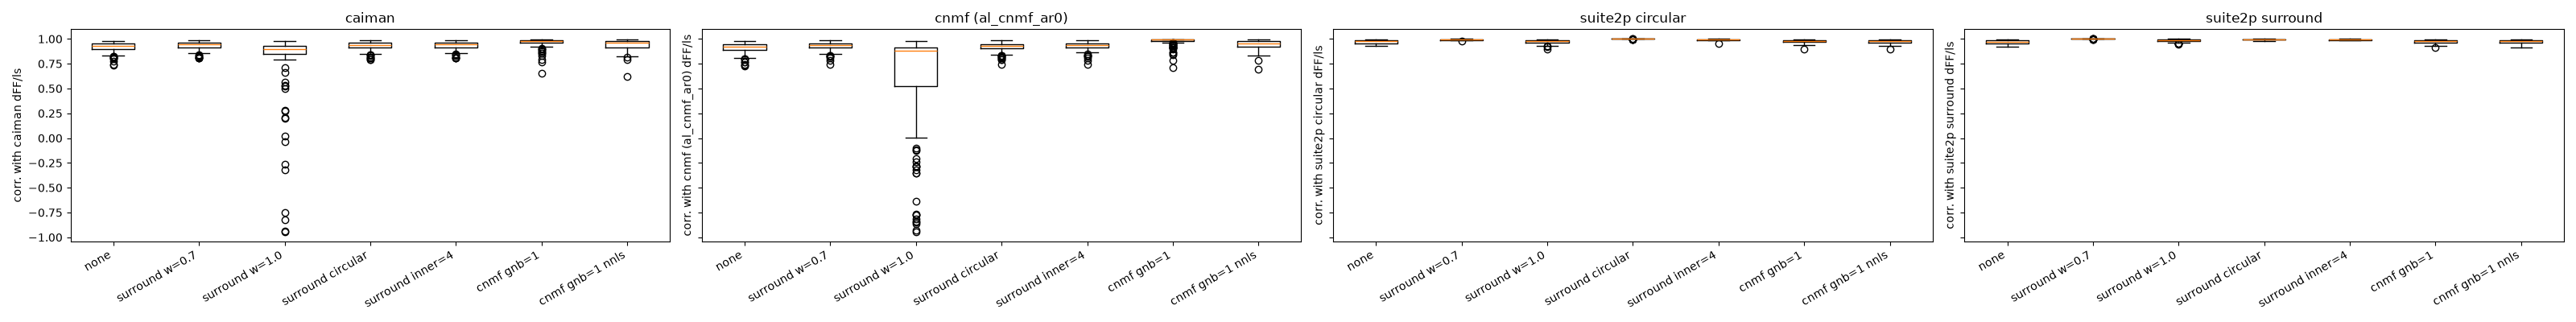

In [37]:
dff_corr = {}
for src, d in data.items():
    dff_corr[src] = {}
    for name in d["results"]:
        dff = compute_dff(src, name, method="maximin")  # (frame, roi)
        dff_corr[src][name] = corr_per_roi(dff, d["ref_dff"].T)[d["iscell"]]
        print(f"[{src}] {name}: median r = {np.nanmedian(dff_corr[src][name]):.3f}")

fig, axes = plt.subplots(1, len(data), figsize=(8 * len(data), 4), squeeze=False, sharey=True)
for ax, (src, corrs) in zip(axes[0], dff_corr.items()):
    ax.boxplot([c[~np.isnan(c)] for c in corrs.values()], tick_labels=list(corrs))
    ax.set_ylabel(f"corr. with {src} dFF/ls")
    ax.set_title(src)
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
fig.savefig(FIG_DIR / "corr_dff_with_extraction_all_sources.pdf", bbox_inches="tight")

## Randomness test: CNMF `gnb=1`

**Runs**: for each unique ROI set, it re-runs the cnmf gnb=1 variant (VARIANTS["cnmf gnb=1"]) 
5 times (N_REPEATS) with identical settings, each time on a fresh analyzer.

**Comparisons**: it compares runs 1–4 against run 0 for three outputs: the spatial background b, 
the fluorescence traces F, and the background traces bg.

**Printed output**: for each output it prints the max absolute difference, that difference 
relative to the max of run 0, and whether all runs are exactly identical.

In [ ]:
N_REPEATS = 5

for roi_set in roi_sets:
    runs = []
    for i in range(N_REPEATS):
        analyzer, ext = run_variant(data[roi_set]["rois"], **VARIANTS["cnmf gnb=1"])
        runs.append(dict(F=ext.get_data(), bg=ext.get_data(key="background"), b=analyzer.get_extension("background").get_data()))
    print(f"ROIs: {roi_set}")
    for key in ("b", "F", "bg"):
        ref = np.asarray(runs[0][key], dtype=np.float64)
        scale = np.abs(ref).max()
        max_abs = [np.abs(np.asarray(r[key], dtype=np.float64) - ref).max() for r in runs[1:]]
        print(f"  {key:>2}: max |run_i - run_0| = {max(max_abs):.3e} (relative to max |run_0|: {max(max_abs) / scale:.3e}), "
              f"identical: {all(np.array_equal(r[key], runs[0][key]) for r in runs[1:])}")